# Vorlesungsnotebook zum Thema Neuronale Netze
    
    
    

In [1]:
import matplotlib.pyplot as plt
from matplotlib import pylab

import numpy as np
from sklearn.datasets import make_blobs

## Das Perzeptron

In [2]:
def step(x):
    return 1 * (x > 0)

(100,)


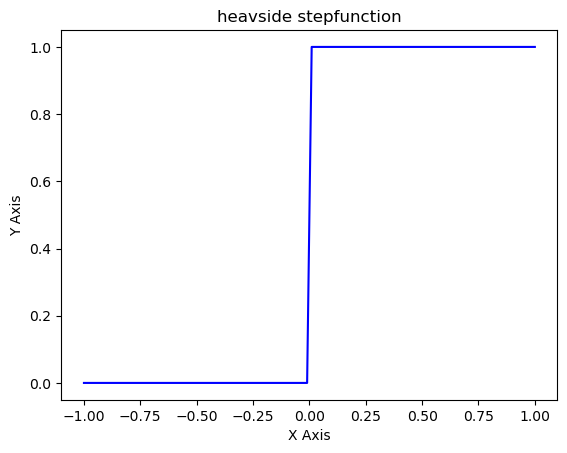

In [3]:
x = pylab.linspace(-1, 1, 100)

print(x.shape)

plt.title('heavside stepfunction')
plt.xlabel('X Axis')
plt.ylabel('Y Axis')

plt.plot(x, step(x), 'b')


### Erzeugen randomisierter Daten

In [4]:
K = 2
N = 100 
D = 2

X , y = make_blobs(n_features = D, n_samples = K * N, centers = K, random_state = 42, cluster_std=1.5)

print(X.shape)
print(y.shape)

print(y[0:10])

(200, 2)
(200,)
[1 1 1 0 1 1 1 1 0 1]


Text(0, 0.5, 'Feature 2')

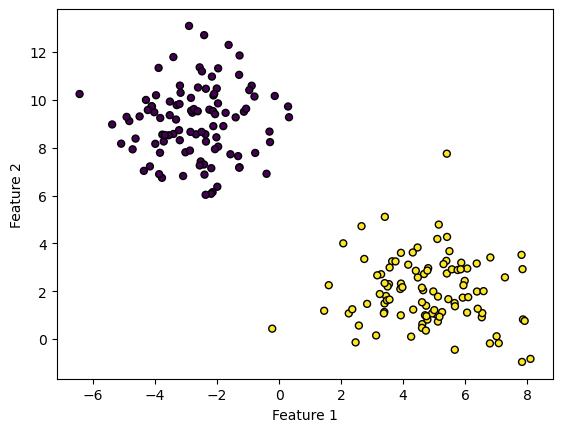

In [5]:
plt.scatter(X[:,0], X[:,1], marker='o', s=25, edgecolor='k', c=y)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

In [6]:
y = np.reshape(y,(-1,1))
print(y.shape)

(200, 1)


### Scoring eines Perzeptrons

In [7]:
#Zufällige Initialisierung der Gewichte

W = 0.01 * np.random.randn(D,1)

b = np.zeros((1,1))


z = np.dot(X,W) + b

y_pred = step(z)

### Schritte des Perzeptron-Trainings

In [8]:
#delta-Regel


dw = np.dot(X.T,(y_pred - y))


step_size = 1e-0

W += -step_size * dw

In [9]:
db = np.sum(y_pred - y, axis =0, keepdims=True)

b += -step_size * db

### Putting it all together

In [10]:
print("Cost beginning: "+str(np.sum((y_pred - y)**2, axis=0)))

for i in range(400):
    
    z = np.dot(X,W + b)
    y_pred = step(z)     #predict step
    
    dw = np.dot(X.T, (y_pred - y))
    W += -step_size * dw
    
    db = np.sum(y_pred - y, axis=0, keepdims=True)
    b += -step_size * db

print("Cost end: "+str(np.sum((y_pred - y)**2, axis=0)))

Cost beginning: [100]
Cost end: [1]


In [11]:
#alternativ, Einbezug des Bias in X und W

#Xtmp = np.ones((N*K,D+1))
#Xtmp[:,1:] = X
#X = Xtmp


#Wtmp = 0.01 * np.random.randn(D,1)
#W = np.zeros((D+1,1))
#W[1:,:] = Wtmp


#print(W)

### Visualisierung des Ergebnisses 

(-1.9549620153430207, 14.085037984656994)

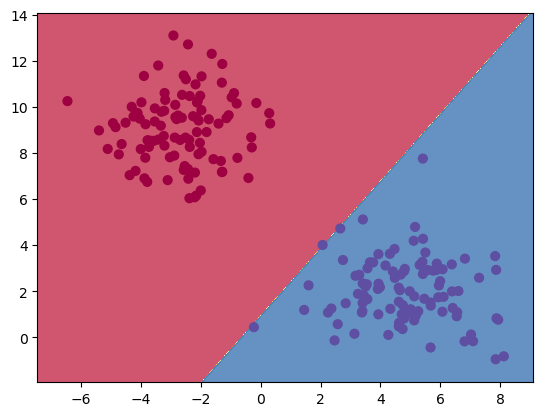

In [12]:
# plot the resulting classifier
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b
Z = step(Z)
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y[:,0], s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())

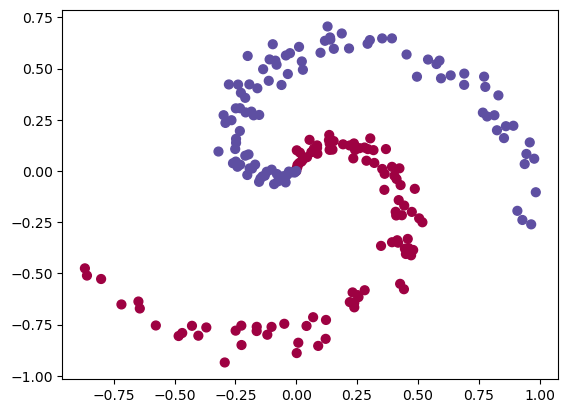

In [13]:
N = 100 # Beispiele pro Klasse
D = 2 # Dimensionalität
K = 2 # Anzahl der Klassen
X = np.zeros((N*K,D)) # Datenmatrix (jede Zeile = ein Beispiel)
y = np.zeros(N*K, dtype='uint8') # Klassenlabel
for j in range(K):
  ix = range(N*j,N*(j+1))
  r = np.linspace(0.0,1,N) # radius
  t = np.linspace(j*4,(j+1)*4,N) + np.random.randn(N)*0.2 # theta
  X[ix] = np.c_[r*np.sin(t), r*np.cos(t)]
  y[ix] = j

# Visualisierung der Daten
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.show()

y=np.reshape(y, (-1, 1))


In [14]:
step_size = 1e-0


# Zufälliges Initialisieren der Parameter
W = 0.01 * np.random.randn(D,1)
b = np.zeros((1,1))

print(W.shape)
print(b.shape)

(2, 1)
(1, 1)


In [15]:
for i in range(200):
    
    scores = np.dot(X, W) + b
    #alternativ: scores = np.dot(X, W)

    y_pred=step(scores)
    dw=np.dot(X.T,(y_pred-y))
    W += -step_size * dw
    #alternativ ohne b auskommentieren   
    db = np.sum(y_pred-y, axis=0, keepdims=True)
    b += -step_size * db


    

(-1.9347320477520036, 1.7052679522479997)

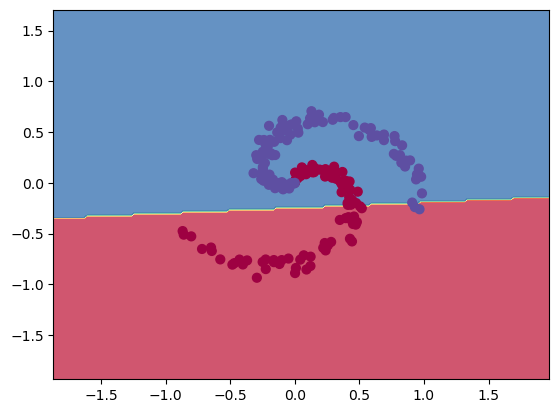

In [16]:
# plot the resulting classifier
h = 0.02
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))
Z = np.dot(np.c_[xx.ravel(), yy.ravel()], W) + b
Z = step(Z)
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y[:,0], s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())


## Neuronale Netze in Tensorflow/Keras

Beispiele unter Verwendung des Datensatzes 
https://www.kaggle.com/uciml/pima-indians-diabetes-database


In [17]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense
from tensorflow.keras import utils
from numpy import loadtxt
from sklearn.model_selection import train_test_split

In [18]:
# load the dataset
dataset = loadtxt('../data/pima-indians-diabetes.csv', delimiter=',')
# split into input (X) and output (y) variables
X = dataset[:,0:8]
y = dataset[:,8]


print(X.shape)
print(y.shape)

(768, 8)
(768,)


In [19]:


X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2,random_state=42)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)

Xtr_std = scaler.transform(X_train)
Xte_std = scaler.transform(X_test)



In [20]:
model = Sequential()
model.add(Dense(8, input_dim=8, activation='sigmoid'))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='sgd', metrics=['accuracy'])



#model.fit(X_train, y_train, epochs=50, batch_size=64)
model.fit(Xtr_std, y_train, epochs=50, batch_size=128)


Epoch 1/50
5/5 [==============================] - 0s 693us/step - loss: 0.8156 - accuracy: 0.3322
Epoch 2/50
5/5 [==============================] - 0s 426us/step - loss: 0.8052 - accuracy: 0.3355
Epoch 3/50
5/5 [==============================] - 0s 429us/step - loss: 0.7956 - accuracy: 0.3257
Epoch 4/50
5/5 [==============================] - 0s 400us/step - loss: 0.7865 - accuracy: 0.3078
Epoch 5/50
5/5 [==============================] - 0s 450us/step - loss: 0.7780 - accuracy: 0.3046
Epoch 6/50
5/5 [==============================] - 0s 416us/step - loss: 0.7701 - accuracy: 0.3160
Epoch 7/50
5/5 [==============================] - 0s 410us/step - loss: 0.7627 - accuracy: 0.3111
Epoch 8/50
5/5 [==============================] - 0s 492us/step - loss: 0.7557 - accuracy: 0.3176
Epoch 9/50
5/5 [==============================] - 0s 540us/step - loss: 0.7493 - accuracy: 0.3192
Epoch 10/50
5/5 [==============================] - 0s 491us/step - loss: 0.7432 - accuracy: 0.3225
Epoch 11/50
5/5 [==

In [21]:
_, accuracy = model.evaluate(Xte_std, y_test,verbose=0) # erstes element ist loss
print('Accuracy SGD: %.2f' % (accuracy*100))

Accuracy SGD: 64.94


## Neuronales Netz auf MNIST

In [22]:
import tensorflow as tf


fashion_mnist = tf.keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

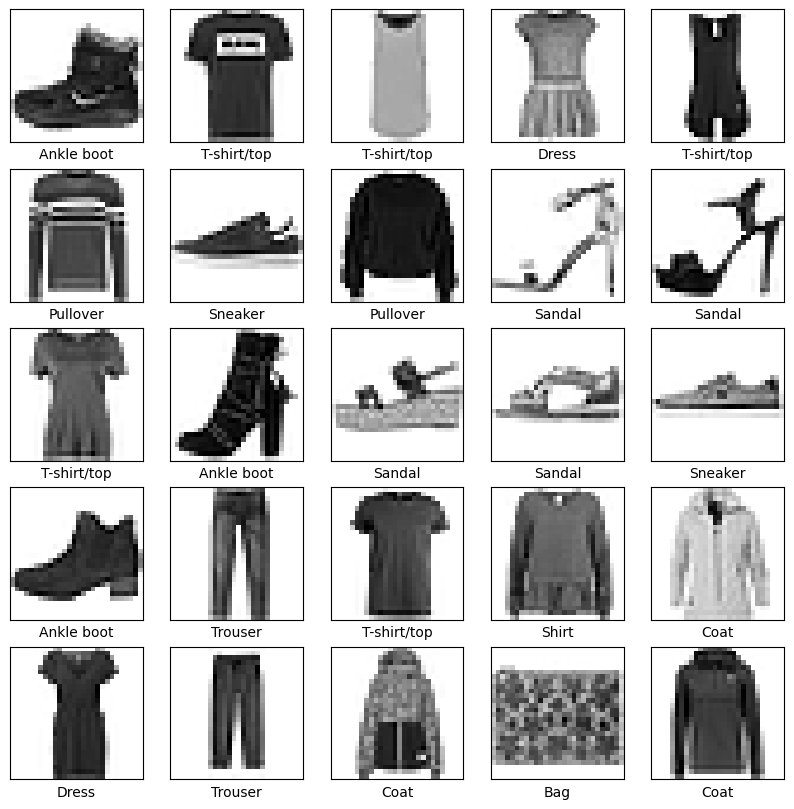

In [23]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[train_labels[i]])
plt.show()

In [24]:
tshirt_indizes_train = np.where(train_labels == 0)[0]
trouser_indizes_train = np.where(train_labels == 1)[0]

tshirt_indizes_test = np.where(test_labels == 0)[0]
trouser_indizes_test = np.where(test_labels == 1)[0]


print(tshirt_indizes_train.shape)
print(trouser_indizes_train.shape)

tt_images = np.append(train_images[tshirt_indizes_train],train_images[trouser_indizes_train],axis=0)
tt_labels = np.append(np.zeros(tshirt_indizes_train.shape[0]),np.ones(trouser_indizes_train.shape[0]),axis=0)

print(tt_labels.shape)

tshirts_test=test_images[tshirt_indizes_test]
trousers_test=test_images[trouser_indizes_test]

(6000,)
(6000,)
(12000,)


In [25]:
# Vorverarbeiten:
tt_images = tt_images / 255.0
tshirts_test = tshirts_test / 255.0
trousers_test = trousers_test / 255.0

train_images = train_images / 255.0
test_images = test_images / 255.0


In [26]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='sigmoid'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])


In [27]:
model.compile(optimizer='sgd',
              loss='binary_crossentropy',metrics=['accuracy'])

In [28]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense_2 (Dense)             (None, 128)               100480    
                                                                 
 dense_3 (Dense)             (None, 1)                 129       
                                                                 
Total params: 100609 (393.00 KB)
Trainable params: 100609 (393.00 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [29]:
model.fit(tt_images, tt_labels, epochs=10)


Epoch 1/10
375/375 [==============================] - 0s 364us/step - loss: 0.4173 - accuracy: 0.9113
Epoch 2/10
375/375 [==============================] - 0s 330us/step - loss: 0.1918 - accuracy: 0.9617
Epoch 3/10
375/375 [==============================] - 0s 333us/step - loss: 0.1400 - accuracy: 0.9649
Epoch 4/10
375/375 [==============================] - 0s 323us/step - loss: 0.1166 - accuracy: 0.9692
Epoch 5/10
375/375 [==============================] - 0s 316us/step - loss: 0.1017 - accuracy: 0.9709
Epoch 6/10
375/375 [==============================] - 0s 316us/step - loss: 0.0907 - accuracy: 0.9732
Epoch 7/10
375/375 [==============================] - 0s 337us/step - loss: 0.0824 - accuracy: 0.9754
Epoch 8/10
375/375 [==============================] - 0s 333us/step - loss: 0.0759 - accuracy: 0.9776
Epoch 9/10
375/375 [==============================] - 0s 334us/step - loss: 0.0708 - accuracy: 0.9793
Epoch 10/10
375/375 [==============================] - 0s 329us/step - loss: 0.066

In [30]:
model.evaluate(tshirts_test,  np.zeros(tshirts_test.shape[0]),verbose=0)
#model.predict(tshirts_test)

[0.05583466961979866, 0.9869999885559082]

In [31]:
model.evaluate(trousers_test,  np.ones(trousers_test.shape[0]),verbose=0)

[0.08760171383619308, 0.9639999866485596]

In [32]:
from tensorflow.keras.utils import to_categorical

labels_onehot = to_categorical(train_labels)

print(train_labels[2])
print(labels_onehot[2])

0
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [33]:
print(train_labels[45])
print(labels_onehot[45])

2
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]


In [34]:
model_sm = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='sigmoid'),
    tf.keras.layers.Dense(10, activation='softmax')
])


In [35]:
model_sm.compile(optimizer='sgd',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [36]:
model_sm.fit(train_images, labels_onehot, epochs=10)


Epoch 1/10
1875/1875 [==============================] - 1s 318us/step - loss: 1.2686 - accuracy: 0.6729
Epoch 2/10
1875/1875 [==============================] - 1s 310us/step - loss: 0.7616 - accuracy: 0.7563
Epoch 3/10
1875/1875 [==============================] - 1s 309us/step - loss: 0.6531 - accuracy: 0.7782
Epoch 4/10
1875/1875 [==============================] - 1s 305us/step - loss: 0.5981 - accuracy: 0.7944
Epoch 5/10
1875/1875 [==============================] - 1s 307us/step - loss: 0.5625 - accuracy: 0.8067
Epoch 6/10
1875/1875 [==============================] - 1s 307us/step - loss: 0.5373 - accuracy: 0.8141
Epoch 7/10
1875/1875 [==============================] - 1s 313us/step - loss: 0.5184 - accuracy: 0.8209
Epoch 8/10
1875/1875 [==============================] - 1s 307us/step - loss: 0.5034 - accuracy: 0.8253
Epoch 9/10
1875/1875 [==============================] - 1s 306us/step - loss: 0.4913 - accuracy: 0.8290
Epoch 10/10
1875/1875 [==============================] - 1s 305u

In [37]:
test_loss, test_acc = model_sm.evaluate(test_images,  to_categorical(test_labels),verbose=0)

print(str(test_acc*100) + "% Erkennungsrate")

82.1399986743927% Erkennungsrate


In [38]:
predictions = model_sm.predict(test_images)


print(predictions[0])



313/313 [==============================] - 0s 215us/step
[9.6901225e-05 6.1483130e-05 2.5153556e-04 2.6620712e-04 2.3713287e-04
 1.4579654e-01 3.6528593e-04 3.1391451e-01 9.1821579e-03 5.2982825e-01]


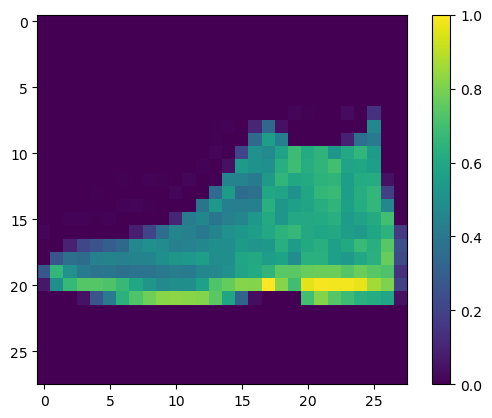

In [39]:

plt.figure()
plt.imshow(test_images[0])
plt.colorbar()
plt.grid(False)
plt.show()

In [40]:
print("Erkannter Klassenindex: "+ str(np.argmax(predictions[0])))

prob=predictions[0][np.argmax(predictions[0])]*100

print("Erkannter Klasse: "+class_names[np.argmax(predictions[0])]
      +" mit Wahrscheinlichkeit "+str(prob)+" %")



Erkannter Klassenindex: 9
Erkannter Klasse: Ankle boot mit Wahrscheinlichkeit 52.98282504081726 %


In [41]:
(predictions[0][7])*100  #Sneaker

31.39145076274872

In [42]:
(predictions[0][8])*100  #Kleid

0.9182157926261425

In [43]:
model_deep = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(256, activation='sigmoid'),
    tf.keras.layers.Dense(128, activation='sigmoid'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [44]:
model_deep.compile(optimizer='sgd',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [45]:
model_deep.fit(train_images, labels_onehot, epochs=20)


Epoch 1/20
1875/1875 [==============================] - 1s 454us/step - loss: 1.9208 - accuracy: 0.4533
Epoch 2/20
1875/1875 [==============================] - 1s 450us/step - loss: 1.2078 - accuracy: 0.6485
Epoch 3/20
1875/1875 [==============================] - 1s 451us/step - loss: 0.9314 - accuracy: 0.7015
Epoch 4/20
1875/1875 [==============================] - 1s 481us/step - loss: 0.7929 - accuracy: 0.7305
Epoch 5/20
1875/1875 [==============================] - 1s 474us/step - loss: 0.7118 - accuracy: 0.7464
Epoch 6/20
1875/1875 [==============================] - 1s 457us/step - loss: 0.6615 - accuracy: 0.7579
Epoch 7/20
1875/1875 [==============================] - 1s 450us/step - loss: 0.6267 - accuracy: 0.7692
Epoch 8/20
1875/1875 [==============================] - 1s 457us/step - loss: 0.5995 - accuracy: 0.7808
Epoch 9/20
1875/1875 [==============================] - 1s 467us/step - loss: 0.5768 - accuracy: 0.7896
Epoch 10/20
1875/1875 [==============================] - 1s 462u